Creating chat based log analyser

In [1]:
import os
import sys
import json
from pathlib import Path

from pydantic import BaseModel, Field
from typing import Annotated, TypedDict, List

from langchain_core.messages import AnyMessage, AIMessage, HumanMessage, SystemMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_aws import ChatBedrockConverse
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver


PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Tools.log_tools import log_fetch_tools

In [2]:
llm_config = {
    'model': "us.anthropic.claude-sonnet-4-6",
    'region_name': "us-east-1"
}
checkpointer = MemorySaver()

llm = ChatBedrockConverse(**llm_config)

In [3]:
# Crete chat state

class ChatState(TypedDict):
    messages: Annotated[List[AnyMessage], add_messages]

### General Chat

In [4]:
def chat_node(state: ChatState) -> ChatState:
    messages = state.get("messages", '')
    response = llm.invoke(messages)
    return {
        'messages': [response]
    }

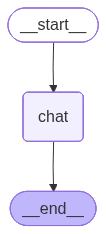

In [12]:
def create_graph():
    builder = StateGraph(ChatState)
    builder.add_node("chat", chat_node)
    builder.add_edge(START, "chat")
    builder.add_edge("chat", END)
    
    graph = builder.compile(checkpointer = checkpointer)
    return graph

graph = create_graph()
graph

In [15]:
thread_id = "test_1"
graph.invoke({
    'messages': [HumanMessage(content = "Hello, how are you?")]
}, config = {'configurable': {'thread_id': thread_id}})

{'messages': [HumanMessage(content='Hello, how are you?', additional_kwargs={}, response_metadata={}, id='c7811b03-9ae4-4c20-9476-185c600944da'),
  AIMessage(content="Hello! I'm doing well, thanks for asking. How are you doing today? Is there something I can help you with?", additional_kwargs={}, response_metadata={'ResponseMetadata': {'RequestId': 'e4e6485f-0f93-4695-8fd7-96644475b6f2', 'HTTPStatusCode': 200, 'HTTPHeaders': {'date': 'Tue, 14 Jul 2026 04:42:38 GMT', 'content-type': 'application/json', 'content-length': '419', 'connection': 'keep-alive', 'x-amzn-requestid': 'e4e6485f-0f93-4695-8fd7-96644475b6f2'}, 'RetryAttempts': 0}, 'stopReason': 'end_turn', 'metrics': {'latencyMs': [1245]}, 'model_provider': 'bedrock_converse', 'model_name': 'us.anthropic.claude-sonnet-4-6'}, id='lc_run--019f5eef-1793-75e3-867d-086b8641617d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_tokens': 29, 'total_tokens': 42, 'input_token_details': {'cache_creation': 0

### With Log tools

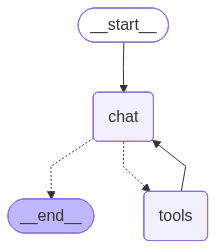

In [25]:
llm_with_tools = llm.bind_tools(log_fetch_tools)
def chat_node(state: ChatState) -> ChatState:
    messages = state.get("messages", '')
    response = llm_with_tools.invoke(messages)
    return {
        'messages': [response]
    }

def create_graph():
    builder = StateGraph(ChatState)
    builder.add_node("chat", chat_node)
    builder.add_node('tools', ToolNode(log_fetch_tools))
    builder.add_edge(START, "chat")
    builder.add_conditional_edges('chat', tools_condition)
    builder.add_edge('tools', "chat")
    
    graph = builder.compile(checkpointer = checkpointer)
    return graph

graph = create_graph()
graph

In [27]:
log_file_path = r'C:\Data\Project\ASBG\LogAnalyser\logs\LOGS_POOL_DUMP\PoolServer1\ServerManager.log'
thread_id = 'test_3'

response = graph.invoke({
    'messages': [
        SystemMessage(content = f"The log file path is {log_file_path}"),
        HumanMessage(content = "Can you give me the latest logs of the system?")
    ]
}, config = {'configurable': {'thread_id': thread_id}})

In [28]:
response

{'messages': [SystemMessage(content='The log file path is C:\\Data\\Project\\ASBG\\LogAnalyser\\logs\\LOGS_POOL_DUMP\\PoolServer1\\ServerManager.log', additional_kwargs={}, response_metadata={}, id='04878e9b-b657-4e04-9408-ca3809cb826a'),
  HumanMessage(content='Can you give me the latest logs of the system?', additional_kwargs={}, response_metadata={}, id='c54aeed8-87ba-4c76-a8b3-49f8f68bbf7a'),
  AIMessage(content=[{'type': 'text', 'text': 'Sure! Let me fetch the latest log entries for you right away.'}, {'type': 'tool_use', 'name': 'latest_logs', 'input': {'file_path': 'C:\\Data\\Project\\ASBG\\LogAnalyser\\logs\\LOGS_POOL_DUMP\\PoolServer1\\ServerManager.log'}, 'id': 'tooluse_oLU8HfNbnteSCFxnskTZkZ'}], additional_kwargs={}, response_metadata={'ResponseMetadata': {'RequestId': 'f4ccaa63-fe69-4323-811a-ef2b532e061e', 'HTTPStatusCode': 200, 'HTTPHeaders': {'date': 'Tue, 14 Jul 2026 05:10:08 GMT', 'content-type': 'application/json', 'content-length': '592', 'connection': 'keep-alive', 

In [31]:
from IPython.display import display, Markdown

Markdown(response['messages'][-1].content)

Here are the **10 latest log entries** from the system, all recorded on **2024-07-17** on host **OITTOR56APCC140**:

| # | Timestamp | Level | Message |
|---|-----------|-------|---------|
| 1 | 05:06:39.091 | INFO | `tcserver00044` **published** — Counts: Total: 9, Assigned: 2, Warm: 6, Warming: 1 |
| 2 | 05:06:39.538 | INFO | `tcserver00046` **launched** — PID=4780 |
| 3 | 05:06:41.340 | INFO | `tcserver00045` **published** — Counts: Total: 10, Assigned: 2, Warm: 7, Warming: 1 |
| 4 | 05:06:42.983 | INFO | `tcserver00046` **published** — Counts: Total: 10, Assigned: 2, Warm: 8 |
| 5 | 07:24:37.849 | INFO | `tcserver00039` **assigned** to `c07441b~TD0374503.SharedSession` |
| 6 | 07:32:19.860 | INFO | `tcserver00032` **removed** |
| 7 | 07:32:19.894 | INFO | `tcserver00032` **finished** |
| 8 | 07:32:20.050 | INFO | `tcserver00047` **launched** — PID=5792 |
| 9 | 07:32:23.707 | INFO | `tcserver00047` **published** — Counts: Total: 10, Assigned: 2, Warm: 8 |
| 10 | 07:34:58.703 | INFO | `tcserver00040` **assigned** to `f05831d~DT0314593.SharedSession` |

---

### 📋 Summary
- **All entries are INFO level** — no warnings or errors detected. ✅
- The pool **CADENAS_QA1_TcPoolA** is actively managing TcServer instances on host `OITTOR56APCC140`.
- The pool appears **healthy**, with servers being launched, published, assigned, and recycled normally.
- The **final pool state** shows: **Total: 10, Assigned: 2, Warm: 8**, which indicates good warm server availability.

Let me know if you'd like to dig deeper into any specific entries or time range!

#### Time based tool calling

In [33]:
log_file_path = r'C:\Data\Project\ASBG\LogAnalyser\logs\LOGS_POOL_DUMP\PoolServer1\ServerManager.log'
thread_id = 'test_4-1'

response = graph.invoke({
    'messages': [
        SystemMessage(content = f"The log file path is {log_file_path}"),
        HumanMessage(content = "Can you summarize the logs between 5:06:40 and 7:32:20 on 2024-07-17?")
    ]
}, config = {'configurable': {'thread_id': thread_id}})

response

{'messages': [SystemMessage(content='The log file path is C:\\Data\\Project\\ASBG\\LogAnalyser\\logs\\LOGS_POOL_DUMP\\PoolServer1\\ServerManager.log', additional_kwargs={}, response_metadata={}, id='c6a6897d-01f9-4099-9e4b-425684ccc523'),
  HumanMessage(content='Can you summarize the logs between 5:06:40 and 7:32:20 on 2024-07-17?', additional_kwargs={}, response_metadata={}, id='12fa5a4e-277e-4d00-aaf0-281b7caa3c95'),
  AIMessage(content=[{'type': 'text', 'text': 'Sure! Let me fetch those logs right away!'}, {'type': 'tool_use', 'name': 'timed_logs', 'input': {'file_path': 'C:\\Data\\Project\\ASBG\\LogAnalyser\\logs\\LOGS_POOL_DUMP\\PoolServer1\\ServerManager.log', 'start_time': '2024-07-17T05:06:40', 'end_time': '2024-07-17T07:32:20'}, 'id': 'tooluse_Ac6TpTmpTOTZdkwRUhRL4Y'}], additional_kwargs={}, response_metadata={'ResponseMetadata': {'RequestId': '6a6bce7b-2b54-43fe-8f67-348a667f14e5', 'HTTPStatusCode': 200, 'HTTPHeaders': {'date': 'Tue, 14 Jul 2026 05:19:07 GMT', 'content-type':

In [34]:
Markdown(response['messages'][-1].content)

Here's a summary of the log entries between **05:06:40** and **07:32:20** on **2024-07-17**, all from host **OITTOR56APCC140** on pool **CADENAS_QA1_TcPoolA@8132**:

---

### 🟢 05:06:41 — TcServer `tcserver00045` Published
- Server `tcserver00045` was successfully **published**.
- **Pool state:** Total: 10 | Assigned: 2 | Warm: 7 | Warming: 1

---

### 🟢 05:06:43 — TcServer `tcserver00046` Published
- Server `tcserver00046` was successfully **published**.
- **Pool state:** Total: 10 | Assigned: 2 | Warm: 8 *(Warming completed — count went from 7+1 to 8)*

---

### 🟢 07:24:38 — TcServer `tcserver00039` Assigned
- Server `tcserver00039` was **assigned** to session `c07441b~TD0374503.SharedSession`.
- Triggered by client/thread `TD0374503`.

---

### 🔴 07:32:19 — TcServer `tcserver00032` Removed & Finished
- Server `tcserver00032` was **removed** from the pool.
- Immediately followed by a **finished** status for the same server.
- Both events were triggered by source `DT0314593.62215.01.f05831d.08124.Mux.Svr.16250`.

---

### 📝 Overall Summary
- The period began with **two servers warming up and being published** into the pool (~05:06).
- There was a **quiet gap** of over 2 hours with no logged activity.
- Activity resumed near the end of the window with a **server assignment** (~07:24) and a **server removal/termination** (~07:32).
- All log entries were at the **INFO** level — **no warnings or errors** were recorded during this period.

In [35]:
response = graph.invoke({
    'messages': [
        HumanMessage(content = "Can you give me potential solutions of the error")
    ]
}, config = {'configurable': {'thread_id': thread_id}})

response

{'messages': [SystemMessage(content='The log file path is C:\\Data\\Project\\ASBG\\LogAnalyser\\logs\\LOGS_POOL_DUMP\\PoolServer1\\ServerManager.log', additional_kwargs={}, response_metadata={}, id='c6a6897d-01f9-4099-9e4b-425684ccc523'),
  HumanMessage(content='Can you summarize the logs between 5:06:40 and 7:32:20 on 2024-07-17?', additional_kwargs={}, response_metadata={}, id='12fa5a4e-277e-4d00-aaf0-281b7caa3c95'),
  AIMessage(content=[{'type': 'text', 'text': 'Sure! Let me fetch those logs right away!'}, {'type': 'tool_use', 'name': 'timed_logs', 'input': {'file_path': 'C:\\Data\\Project\\ASBG\\LogAnalyser\\logs\\LOGS_POOL_DUMP\\PoolServer1\\ServerManager.log', 'start_time': '2024-07-17T05:06:40', 'end_time': '2024-07-17T07:32:20'}, 'id': 'tooluse_Ac6TpTmpTOTZdkwRUhRL4Y'}], additional_kwargs={}, response_metadata={'ResponseMetadata': {'RequestId': '6a6bce7b-2b54-43fe-8f67-348a667f14e5', 'HTTPStatusCode': 200, 'HTTPHeaders': {'date': 'Tue, 14 Jul 2026 05:19:07 GMT', 'content-type':

In [36]:
Markdown(response['messages'][-1].content)

There are no errors in the logs from that time range — all **5 entries were at the INFO level**. Here's a quick recap:

- ✅ Two TcServers **published** successfully (~05:06)
- ✅ One TcServer **assigned** to a session (~07:24)
- ✅ One TcServer **removed and finished** cleanly (~07:32)

No warnings or errors were detected, so there are no issues to provide solutions for! 😊

Would you like me to check a **different time range** or look for **specific error types** in the logs?

In [37]:
response = graph.invoke({
    'messages': [
        HumanMessage(content = "When was the system last restarted?")
    ]
}, config = {'configurable': {'thread_id': thread_id}})

response

{'messages': [SystemMessage(content='The log file path is C:\\Data\\Project\\ASBG\\LogAnalyser\\logs\\LOGS_POOL_DUMP\\PoolServer1\\ServerManager.log', additional_kwargs={}, response_metadata={}, id='c6a6897d-01f9-4099-9e4b-425684ccc523'),
  HumanMessage(content='Can you summarize the logs between 5:06:40 and 7:32:20 on 2024-07-17?', additional_kwargs={}, response_metadata={}, id='12fa5a4e-277e-4d00-aaf0-281b7caa3c95'),
  AIMessage(content=[{'type': 'text', 'text': 'Sure! Let me fetch those logs right away!'}, {'type': 'tool_use', 'name': 'timed_logs', 'input': {'file_path': 'C:\\Data\\Project\\ASBG\\LogAnalyser\\logs\\LOGS_POOL_DUMP\\PoolServer1\\ServerManager.log', 'start_time': '2024-07-17T05:06:40', 'end_time': '2024-07-17T07:32:20'}, 'id': 'tooluse_Ac6TpTmpTOTZdkwRUhRL4Y'}], additional_kwargs={}, response_metadata={'ResponseMetadata': {'RequestId': '6a6bce7b-2b54-43fe-8f67-348a667f14e5', 'HTTPStatusCode': 200, 'HTTPHeaders': {'date': 'Tue, 14 Jul 2026 05:19:07 GMT', 'content-type':

In [38]:
Markdown(response['messages'][-1].content)

Based on the logs, there is no explicit "restart" event logged. However, there are strong indicators of a system restart or pool reinitialization. Here's what the logs suggest:

---

### 🔄 Most Likely Last Restart: **2024-07-17 at ~05:06:31**

#### Evidence:
- There is a **significant gap** in activity between **2024-07-16 15:46:30** (last entry of the previous day) and **2024-07-17 05:06:31** — roughly **~13.5 hours of inactivity**.
- At **05:06:31**, a **burst of TcServer launches** began in rapid succession:

| Time | Event |
|------|-------|
| 05:06:31 | `tcserver00042` launched (PID=7820) |
| 05:06:33 | `tcserver00043` launched (PID=8744) |
| 05:06:35 | `tcserver00042` published — Pool: Total: 7, Warm: 4 |
| 05:06:35 | `tcserver00044` launched (PID=10528) |
| 05:06:37 | `tcserver00043` published — Pool: Total: 8, Warm: 5 |
| 05:06:37 | `tcserver00045` launched (PID=6256) |
| 05:06:39 | `tcserver00044` published — Pool: Total: 9, Warm: 6 |
| 05:06:39 | `tcserver00046` launched (PID=4780) |
| 05:06:41 | `tcserver00045` published — Pool: Total: 10, Warm: 7 |
| 05:06:42 | `tcserver00046` published — Pool: Total: 10, Warm: 8 ✅ |

- This pattern of **multiple servers launching and warming up simultaneously** is characteristic of a **pool startup or system restart**.

---

### ⚠️ Note
The logs don't contain an explicit restart/shutdown message. If you need more precise confirmation, it may be worth checking a **system-level or service log** alongside this file. Would you like me to investigate further?

### Using Pydantic

Single LLM can't have both structed output + Tools 
Need to use 2 models -> Orch (deciding the tool call? - Haiku) + Ans Gen(Generating Answer - Sonnet - with output structure)

Testing

In [5]:
class Person(BaseModel):
    name: str = Field(..., description="The name of the person")
    age: int = Field(..., description="The age of the person")
    email: str = Field(..., description="The email address of the person")

class TestState(TypedDict):
    person: Person | None

test_llm = llm.with_structured_output(Person)

def test_person(state: TestState) -> TestState:
    person = test_llm.invoke("Please provide the details of a random person")
    return {
        'person': person
    }

test_builder = StateGraph(TestState)
test_builder.add_node("test_person", test_person)
test_builder.add_edge(START, "test_person")
test_builder.add_edge('test_person', END)

tg = test_builder.compile()
tg.invoke({})

{'person': Person(name='James Carter', age=34, email='james.carter@email.com')}

#### Code structure

In [21]:
class IssueReport(BaseModel):
    category: str = Field(description = 'Category of the issue. It can be one of the following: Bug, Performance Issue, Security Issue, Others, etc. The category should be determined based on the nature of the issue and its impact on the system.')
    priority: str = Field(description = 'Priority of the issue. It can be one of the following: P1, P2, P3, P4. Where P1 is the highest priority and P4 is the lowest priority. The priority should be determined based on the severity of the issue and its impact on the system.')
    issue: str = Field(description = 'A brief description of the issue. It should provide enough information to understand the nature of the problem and its impact on the system.')
    generic_recommendation: str | None = Field(description = 'A generic recommendation for addressing the issue. It should provide a high-level suggestion for resolving the problem, without going into specific implementation details.')
    specific_recommendation: str | None = Field(description = 'A specific recommendation for addressing the issue. It should only be provided if there is mention of the solution in the docs provided else None.', default = None)
    solution_steps: List[str] | None = Field(description = 'A list of specific steps in order to implement the solution. It should only be provided if there is mention of the solution in the docs provided else None.', default = None)

class IssuesReported(BaseModel):
    issues: List[IssueReport] = Field(description = 'A list of issues reported. Each issue should be represented as an instance of the IssueReport model, providing detailed information about the issue, its category, priority, and recommendations for resolution.')

In [ ]:
main_llm_config = {
    'model': "us.anthropic.claude-sonnet-4-6",
    'region_name': "us-east-1"
}
tool_llm_config = {
    # Use inference profile ID from list_inference_profiles(), NOT list_foundation_models()
    'model': "us.anthropic.claude-haiku-4-5-20251001-v1:0",
    'region_name': "us-east-1"
}
checkpointer = MemorySaver()

main_llm = ChatBedrockConverse(**main_llm_config).with_structured_output(IssuesReported)
tool_llm = ChatBedrockConverse(**tool_llm_config).bind_tools(log_fetch_tools)

In [ ]:
from operator import add

class FlowState(TypedDict):
    messages: Annotated[List[AnyMessage], add_messages]
    logs: Annotated[List[dict], add]
    issues: IssuesReported | None

In [ ]:
from langchain_core.messages import ToolMessage

_log_tool_node = ToolNode(log_fetch_tools)


def _parse_tool_logs(content) -> list[dict]:
    if isinstance(content, list):
        return [entry for entry in content if isinstance(entry, dict)]
    if isinstance(content, str):
        try:
            parsed = json.loads(content)
        except json.JSONDecodeError:
            return []
        if isinstance(parsed, list):
            return [entry for entry in parsed if isinstance(entry, dict)]
    return []


def _format_issue_item(issue_item: IssueReport) -> str:
    lines = [
        f"Category: {issue_item.category}",
        f"Priority: {issue_item.priority}",
        f"Issue: {issue_item.issue}",
    ]
    if issue_item.generic_recommendation:
        lines.append(f"Generic recommendation: {issue_item.generic_recommendation}")
    if issue_item.specific_recommendation:
        lines.append(f"Specific recommendation: {issue_item.specific_recommendation}")
    if issue_item.solution_steps:
        lines.append("Solution steps:")
        lines.extend(f"  - {step}" for step in issue_item.solution_steps)
    return "\n".join(lines)


def issues_to_message(reported: IssuesReported) -> AIMessage:
    if not reported.issues:
        return AIMessage(content="No issues were identified in the analyzed logs.")

    issue_blocks = [
        f"Issue {index}:\n{_format_issue_item(item)}"
        for index, item in enumerate(reported.issues, start=1)
    ]
    return AIMessage(
        content="\n\n".join(issue_blocks),
        additional_kwargs={"issues_report": reported.model_dump()},
    )


def orch_node(state: FlowState) -> FlowState:
    messages = state.get('messages', '')
    response = tool_llm.invoke(messages)
    return {'messages': [response]}


def tools_node(state: FlowState) -> FlowState:
    result = _log_tool_node.invoke(state)
    fetched_logs: list[dict] = []
    for message in result.get('messages', []):
        if isinstance(message, ToolMessage):
            fetched_logs.extend(_parse_tool_logs(message.content))
    return {
        'messages': result.get('messages', []),
        'logs': fetched_logs,
    }


def resp_node(state: FlowState) -> FlowState:
    messages = state.get('messages', '')
    reported = main_llm.invoke(messages)
    return {
        'messages': [issues_to_message(reported)],
        'issues': reported,
    }

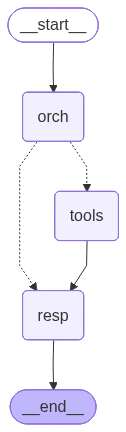

In [25]:
builder = StateGraph(FlowState)
builder.add_node('orch', orch_node)
builder.add_node('tools', tools_node)
builder.add_node('resp', resp_node)

builder.add_edge(START, 'orch')
builder.add_conditional_edges('orch', tools_condition, ['tools', 'resp'])
builder.add_edge('tools', 'resp')
builder.add_edge('resp', END)

graph = builder.compile(checkpointer = checkpointer)
graph

In [ ]:
log_file_path = r'C:\Data\Project\ASBG\LogAnalyser\logs\LOGS_POOL_DUMP\PoolServer1\ServerManager.log'
thread_id = 'test_2'

response = graph.invoke({
    'messages': [
        SystemMessage(content = f"The log file path is {log_file_path}"),
        HumanMessage(content = "Can you give me the latest logs of the system?")
    ]
}, config = {'configurable': {'thread_id': thread_id}})
response['issues']

IssuesReported(issues=[])

In [13]:
response.keys()

dict_keys(['messages', 'logs', 'issues'])

In [14]:
response['messages']

[SystemMessage(content='The log file path is C:\\Data\\Project\\ASBG\\LogAnalyser\\logs\\LOGS_POOL_DUMP\\PoolServer1\\ServerManager.log', additional_kwargs={}, response_metadata={}, id='23a03878-7143-4e4d-8848-b86ea16e7f2d'),
 HumanMessage(content='Can you give me the latest logs of the system?', additional_kwargs={}, response_metadata={}, id='0ccc24f7-1d82-4b23-bab8-376ad0128470'),
 AIMessage(content=[{'type': 'text', 'text': "I'll fetch the latest logs from the ServerManager.log file for you."}, {'type': 'tool_use', 'name': 'latest_logs', 'input': {'file_path': 'C:\\Data\\Project\\ASBG\\LogAnalyser\\logs\\LOGS_POOL_DUMP\\PoolServer1\\ServerManager.log'}, 'id': 'tooluse_yCJcdKkiFefwyMgEIWqJpg'}], additional_kwargs={}, response_metadata={'ResponseMetadata': {'RequestId': '1fe16e8c-9e03-491e-b670-a24001235241', 'HTTPStatusCode': 200, 'HTTPHeaders': {'date': 'Tue, 14 Jul 2026 09:27:25 GMT', 'content-type': 'application/json', 'content-length': '598', 'connection': 'keep-alive', 'x-amzn-r

In [26]:
log_file_path = r'C:\Data\Project\ASBG\LogAnalyser\logs\LOGS_POOL_DUMP\PoolServer1\ServerManager.log'
thread_id = 'test_2'

response = graph.invoke({
    'messages': [
        SystemMessage(content = f"The log file path is {log_file_path}"),
        HumanMessage(content = "Can you analyse the logs from 6:30 to 8:00 on 2024-07-15?")
    ]
}, config = {'configurable': {'thread_id': thread_id}})
response

{'messages': [SystemMessage(content='The log file path is C:\\Data\\Project\\ASBG\\LogAnalyser\\logs\\LOGS_POOL_DUMP\\PoolServer1\\ServerManager.log', additional_kwargs={}, response_metadata={}, id='2781f66e-006e-4943-985f-7d9cc5093d35'),
  HumanMessage(content='Can you analyse the logs from 6:30 to 8:00 on 2024-07-15?', additional_kwargs={}, response_metadata={}, id='79e5fc72-5ba2-4dfe-93d8-5d0295e46198'),
  AIMessage(content=[{'type': 'text', 'text': "I'll fetch the logs from that specific time range for you."}, {'type': 'tool_use', 'name': 'timed_logs', 'input': {'file_path': 'C:\\Data\\Project\\ASBG\\LogAnalyser\\logs\\LOGS_POOL_DUMP\\PoolServer1\\ServerManager.log', 'start_time': '2024-07-15T06:30:00', 'end_time': '2024-07-15T08:00:00', 'n': 20}, 'id': 'tooluse_36xbfSu3CMHLTHZnUaNWOL'}], additional_kwargs={}, response_metadata={'ResponseMetadata': {'RequestId': 'c7697f1f-3a9a-460c-9413-53c88d77ba1e', 'HTTPStatusCode': 200, 'HTTPHeaders': {'date': 'Tue, 14 Jul 2026 09:37:54 GMT', '

In [27]:
response['issues'].model_dump()

{'issues': [{'category': 'Performance Issue',
   'priority': 'P2',
   'issue': "TcServer tcserver00012@CADENAS_QA1_TcPoolB@3532@OITTOR56APCC150 lock expired at 07:01:39. The server lock associated with session 'CADENAS_QA1_TcPoolB@29@1721026599763@getAuthenticatedAssignedServer@1' timed out, indicating that the server was held longer than the allowed lock duration.",
   'generic_recommendation': 'Investigate the root cause of the lock expiry. This could be due to long-running operations, unresponsive clients, or misconfigured lock timeout settings. Review server load and session management configurations to prevent premature lock expiration.',
   'specific_recommendation': None,
   'solution_steps': None},
  {'category': 'Bug',
   'priority': 'P1',
   'issue': "Login failure for user 'c22478b' on tcserver00012@CADENAS_QA1_TcPoolB@3532@OITTOR56APCC150 at 07:03:17. The server was locked by another session ('CADENAS_QA1_TcPoolA@25@1721026899803@getAuthenticatedAssignedServer@1'), preventi

In [28]:
response.keys()

dict_keys(['messages', 'logs', 'issues'])

In [29]:
from pprint import pprint
pprint(response['messages'])

[SystemMessage(content='The log file path is C:\\Data\\Project\\ASBG\\LogAnalyser\\logs\\LOGS_POOL_DUMP\\PoolServer1\\ServerManager.log', additional_kwargs={}, response_metadata={}, id='2781f66e-006e-4943-985f-7d9cc5093d35'),
 HumanMessage(content='Can you analyse the logs from 6:30 to 8:00 on 2024-07-15?', additional_kwargs={}, response_metadata={}, id='79e5fc72-5ba2-4dfe-93d8-5d0295e46198'),
 AIMessage(content=[{'type': 'text', 'text': "I'll fetch the logs from that specific time range for you."}, {'type': 'tool_use', 'name': 'timed_logs', 'input': {'file_path': 'C:\\Data\\Project\\ASBG\\LogAnalyser\\logs\\LOGS_POOL_DUMP\\PoolServer1\\ServerManager.log', 'start_time': '2024-07-15T06:30:00', 'end_time': '2024-07-15T08:00:00', 'n': 20}, 'id': 'tooluse_36xbfSu3CMHLTHZnUaNWOL'}], additional_kwargs={}, response_metadata={'ResponseMetadata': {'RequestId': 'c7697f1f-3a9a-460c-9413-53c88d77ba1e', 'HTTPStatusCode': 200, 'HTTPHeaders': {'date': 'Tue, 14 Jul 2026 09:37:54 GMT', 'content-type': 